# Exploration des données d'images (EDA)

Ce notebook explore un jeu d'images avant l'entraînement d'un modèle de deep learning : nombre d'images, classes, dimensions, formats, tailles de fichiers, images illisibles et exemples visuels.

Organisation attendue dans le dossier du notebook : `yes/image.jpg` et `no/image.jpg` (ou `train/yes/image.jpg` et `train/no/image.jpg`). L'étiquette est prise depuis le dossier parent de chaque image.

In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError

sns.set_theme(style="whitegrid")

# Le dossier courant contient les sous-dossiers de classes yes et no.
DATA_DIR = Path(".")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASS_NAMES = {"yes", "no"}

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dossier introuvable : {DATA_DIR.resolve()}. Modifie DATA_DIR pour indiquer le chemin de tes images."
    )

image_paths = sorted(
    path for path in DATA_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in IMAGE_EXTENSIONS
    and any(parent.name.lower() in CLASS_NAMES for parent in path.parents)
)

if not image_paths:
    raise ValueError(
        f"Aucune image trouvée dans {DATA_DIR.resolve()}. Vérifie le chemin et les extensions prises en charge."
    )

print(f"Images trouvées : {len(image_paths)}")
print(f"Dossier analysé : {DATA_DIR.resolve()}")

Images trouvées : 2999
Dossier analysé : C:\Users\Mahamadou\Documents\DL\Tumeur


## Création du tableau de métadonnées

L'étiquette (`label`) est le nom du dossier parent de chaque image. Les fichiers corrompus ou illisibles sont ignorés et comptabilisés.

In [11]:
records = []
failed_images = []

for image_path in image_paths:
    try:
        with Image.open(image_path) as image:
            width, height = image.size
            channels = len(image.getbands())
            image_format = image.format

        records.append({
            "path": str(image_path),
            "label": next(
                parent.name.lower()
                for parent in image_path.parents
                if parent.name.lower() in CLASS_NAMES
            ),
            "format": image_format,
            "width": width,
            "height": height,
            "channels": channels,
            "size_kb": image_path.stat().st_size / 1024,
        })
    except (UnidentifiedImageError, OSError, ValueError) as error:
        failed_images.append((str(image_path), str(error)))

df = pd.DataFrame(records)
print(f"Images analysées : {len(df)}")
print(f"Images illisibles : {len(failed_images)}")

if df.empty:
    raise ValueError("Aucune image valide n'a pu être lue.")

if failed_images:
    print("\nQuelques fichiers illisibles :")
    for path, error in failed_images[:10]:
        print(f"- {path}: {error}")

df.head()

Images analysées : 2999
Images illisibles : 0


,path,label,format,width,height,channels,size_kb
0,no\no0.jpg,no,JPEG,630,630,3,48.000977
1,no\no1.jpg,no,JPEG,150,198,3,8.369141
2,no\no10.jpg,no,JPEG,225,225,3,8.145508
3,no\no100.jpg,no,JPEG,232,217,3,14.483398
4,no\no1000.jpg,no,JPEG,259,194,3,7.174805


## Taille, types et statistiques descriptives

In [3]:
print(f"Nombre d'images valides : {len(df)}")
print(f"Nombre de classes : {df['label'].nunique()}")

df.info()

Nombre d'images valides : 3000
Nombre de classes : 2
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   path      3000 non-null   object 
 1   label     3000 non-null   object 
 2   format    3000 non-null   object 
 3   width     3000 non-null   int64  
 4   height    3000 non-null   int64  
 5   channels  3000 non-null   int64  
 6   size_kb   3000 non-null   float64
dtypes: float64(1), int64(3), object(3)
memory usage: 164.2+ KB


In [12]:
# Statistiques des variables numériques
display(df.describe())

# Résumé des variables catégorielles
display(df[["label", "format"]].describe())

# Valeurs manquantes par colonne
display(df.isna().sum().rename("valeurs_manquantes").to_frame())

,width,height,channels,size_kb
count,2999.000000,2999.000000,2999.000000,2999.000000
mean,325.268756,352.828610,2.930310,22.204421
std,174.397894,182.824175,0.370904,26.489905
min,150.000000,167.000000,1.000000,3.393555
25%,225.000000,225.000000,3.000000,9.772949
50%,270.000000,303.000000,3.000000,15.087891
75%,359.000000,380.000000,3.000000,24.768066
max,1920.000000,1427.000000,4.000000,710.845703


,label,format
count,2999,2999
unique,2,2
top,yes,JPEG
freq,1500,2986


,valeurs_manquantes
path,0
label,0
format,0
width,0
height,0
channels,0
size_kb,0


## Équilibre des classes

In [13]:
class_counts = df["label"].value_counts().sort_values(ascending=False)
class_summary = pd.DataFrame({
    "nombre_images": class_counts,
    "pourcentage": (class_counts / len(df) * 100).round(2),
})
display(class_summary)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Rapport classe la plus représentée / moins représentée : {imbalance_ratio:.2f}")

,nombre_images,pourcentage
label,,
yes,1500,50.02
no,1499,49.98


Rapport classe la plus représentée / moins représentée : 1.00


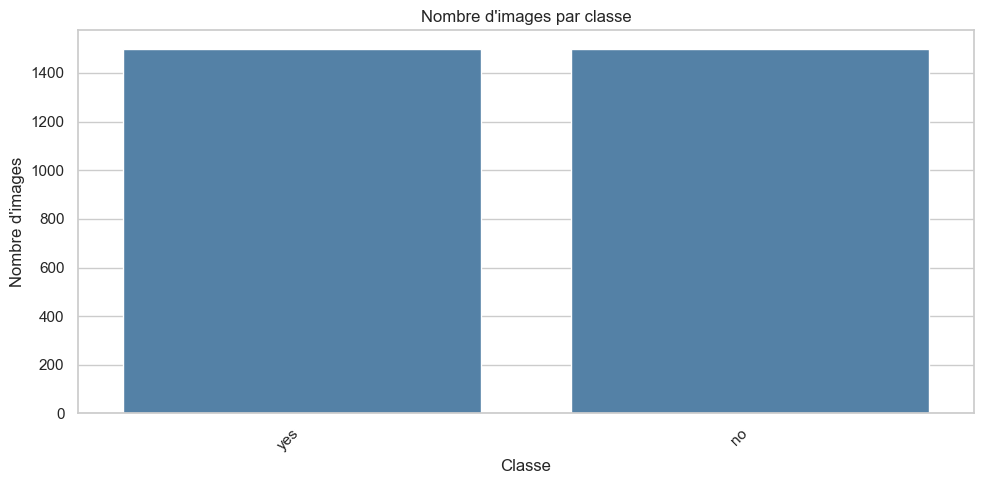

In [14]:
plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.title("Nombre d'images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Distributions des dimensions et formats

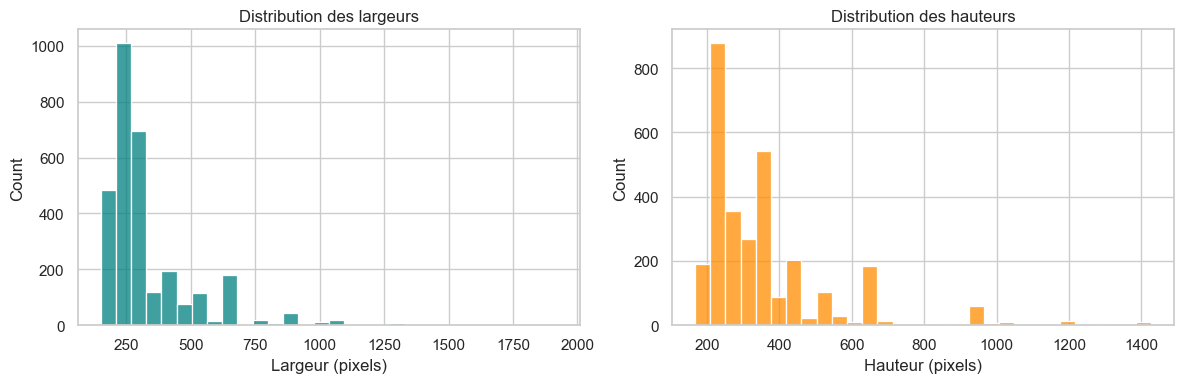

,nombre_images
format,
JPEG,2986
PNG,13


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["width"], bins=30, ax=axes[0], color="teal")
axes[0].set_title("Distribution des largeurs")
axes[0].set_xlabel("Largeur (pixels)")

sns.histplot(df["height"], bins=30, ax=axes[1], color="darkorange")
axes[1].set_title("Distribution des hauteurs")
axes[1].set_xlabel("Hauteur (pixels)")
plt.tight_layout()
plt.show()

display(df["format"].value_counts().rename_axis("format").to_frame("nombre_images"))

## Corrélations entre métadonnées numériques

Cette corrélation concerne les métadonnées (dimensions, canaux et taille des fichiers), pas les pixels des images.

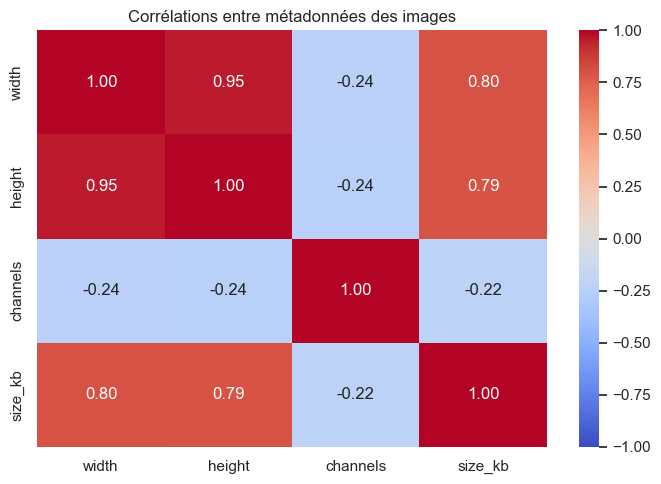

In [16]:
numeric_columns = ["width", "height", "channels", "size_kb"]
correlation = df[numeric_columns].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Corrélations entre métadonnées des images")
plt.tight_layout()
plt.show()

## Exemples d'images par classe

Affiche jusqu'à trois images par classe, et jusqu'à huit classes pour garder une figure lisible.

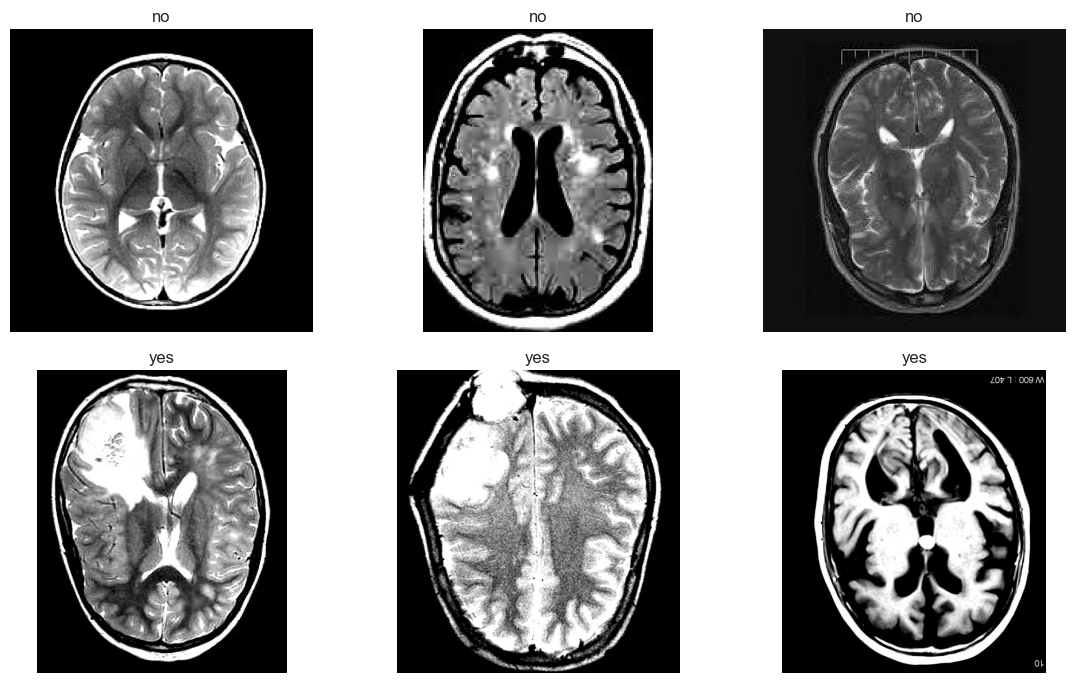

In [17]:
classes = sorted(df["label"].unique())[:8]
images_per_class = 3
fig, axes = plt.subplots(
    len(classes), images_per_class,
    figsize=(4 * images_per_class, 3.5 * len(classes)),
    squeeze=False,
)

for row, label in enumerate(classes):
    samples = df.loc[df["label"] == label, "path"].head(images_per_class).tolist()
    for col in range(images_per_class):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(samples):
            try:
                with Image.open(samples[col]) as image:
                    ax.imshow(image.copy())
                ax.set_title(label)
            except (UnidentifiedImageError, OSError, ValueError) as error:
                ax.set_title(f"Image illisible\n{error}")

plt.tight_layout()
plt.show()